In [ ]:
import os
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model 
from langchain_tavily import TavilySearch # web search
from langchain.agents import create_agent 
from langgraph.checkpoint.memory import MemorySaver # Memory for teh agent's context
load_dotenv()  # Load environment variables from .env file

os.environ["OPENAI_API_KEY"]=os.getenv("OPENAI_API_KEY")

memory = MemorySaver()
llmGPT = init_chat_model("gpt-4.1") # initialize a chat model with the name "gpt-4"
tavilyTool = TavilySearch(max_results=2) #tavily object 
config = {"configurable" : {"thread_id" : "1"}} #config thread

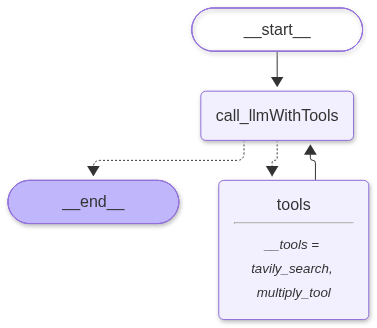

In [ ]:
#StateGraph
from typing import Annotated
from langgraph.graph.message import add_messages
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode, tools_condition #langraph has a prebuilt node specifaclly for tools


#--------------------------------state--------------------------------
class State(TypedDict):
    messages: Annotated[list, add_messages]

#--------------------------------Tools--------------------------------
def multiply_tool(a: int, b: int) -> int: 
    """The tool multiples the value of a(int) and b (int) and retuns the output as an int"""
    return a * b


# #we can add all the tools we have got in this list, and then use the bind_tools method to bind them
tools = [tavilyTool, multiply_tool]


# Binding tools to the LLM only tells the LLM which tools are available and how to request them. 
# It does not execute the tools, A ToolNode actually executes that requested tool
llm_with_tools = llmGPT.bind_tools(tools) 

def tool_callingllm(state: State):
    return {"messages" : [llm_with_tools.invoke(state["messages"])]}


#--------------------------------graphs initilazions--------------------------------
graph_builder = StateGraph(State)
graph_builder.add_node("call_llmWithTools", tool_callingllm)

#we cannot name tools, wtv we want here, as when we create graph_builder.add_conditional_edges("call_llmWithTools", tools_condition) 
# tools_condition returns the actual target name of the list which is "tools" so we have to name it same here.
graph_builder.add_node("tools", ToolNode(tools)) # A ToolNode actually executes that requested tool


# --------------------------------Add the Edges--------------------------------

# Add the Edges, while following the ReACT Formula, Check Images
graph_builder.add_edge(START, "call_llmWithTools")

# if the latest message(result) from the AI assitant is a tool call -> tool_conditon routes to tools
# if the latest message(result) from the AI assitant is not a tool call -> tool_conditon routes to END
graph_builder.add_conditional_edges("call_llmWithTools", tools_condition)
graph_builder.add_edge("tools", "call_llmWithTools") 
graph_builder.add_edge("call_llmWithTools", END) 


#--------------------------------compile the graph--------------------------------
graph = graph_builder.compile(checkpointer=memory) # add MemorySaver for Context
graph

In [81]:

response = graph.invoke({"messages" : "What is the Weather of Vamcouver right now after that add 5 * 2?"}, config=config) # it calls both the tools

#To get staright to the response uncomment:
# message = response["messages"][-1].content
# message

# We can see the Calls and Messages
message = response["messages"]

for m in message:
    m.pretty_print()

================================ Human Message =================================

Hi my name is lucifer.
================================== Ai Message ==================================

Hello, Lucifer! How can I assist you today?
================================ Human Message =================================

Hi my name is lucifer.
================================== Ai Message ==================================

Hello again, Lucifer! How can I help you today? If you have any questions or need assistance, feel free to ask.
================================ Human Message =================================

What is the Weather of Vamcouver right now after that add 5 * 2?
================================== Ai Message ==================================
Tool Calls:
  tavily_search (call_3ex6snndF0H2R3efuFJrXsbP)
 Call ID: call_3ex6snndF0H2R3efuFJrXsbP
  Args:
    query: current weather in Vancouver
    search_depth: fast
  multiply_tool (call_ffrirYmwXyLkV57QtonV0a6u)
 Call ID: call_ffrirYmw

## Adding Memory to Agentic Graph 

We did that by importing, Creating an object, and configuring it with compile method:
- from langgraph.checkpoint.memory import MemorySaver
- memory = MemorySaver()
- graph = graph_builder.compile(checkpointer=memory) 

Then we create a thread id, as it will make the memory for 1 thread session.

config = {"configurable" : {"thread_id" : "1"}}

In [ ]:

# response = graph.invoke({ "messages" :"My name is sehaj!"}, config=config) 

# message = response["messages"][-1].content
# message

#if we run, it will tell me my name, beacuse of the prev memory Context in MemorySaver
response = graph.invoke({ "messages" : "What is my name??"}, config=config) 

message = response["messages"][-1].content
message

'Your name is Sehaj!'

## Streaming 

Methods: stream() and astream()
- These methods sync and async method for stereaming back the results.

Additional Parameters in streaming modes for graph state:
- **Values**: This streams the full state of the graph after each node is called, basically all the messages inclduing Human and AI, Use it when you want the complete current conversation/state each time.
- **Updates**: This streams updates to the state of the graph after each node is called, Use it when you only need to know what each node added or changed.

In [70]:
#Create a new thread 
configuration = {"configurable" : {"thread_id" : "3"}}

for chunk in graph.stream({"messages" : "Hi my name is lucifer."}, config=configuration, stream_mode="updates"):
    for m in chunk['call_llmWithTools']['messages']:
        m.pretty_print()

================================== Ai Message ==================================

Hello, Lucifer! How can I help you today? If you have anything on your mind or need assistance, just let me know!


In [72]:

for chunk in graph.stream({"messages" : "Hi my name is lucifer."}, config=configuration, stream_mode="values"):
    for m in chunk['messages']:
        m.pretty_print()

================================ Human Message =================================

Hi my name is Sehaj.
================================== Ai Message ==================================

Hello Sehaj! Nice to meet you. How can I help you today?
================================ Human Message =================================

Hi my name is MAGA.
================================== Ai Message ==================================

Hello MAGA! How can I assist you today?
================================ Human Message =================================

Hi my name is lucifer.
================================== Ai Message ==================================

Hello Lucifer! How can I help you today?
================================ Human Message =================================

Hi my name is lucifer.
================================== Ai Message ==================================

Hello again, Lucifer! How can I assist you today? If there’s anything specific you’d like to talk about or ask, just le

In [ ]:
#Create a new thread 
config = {"configurable" : {"thread_id" : "6"}}

#astream_events -> lets you observe detailed events while a LangGraph runs—such as node starts, node completions, 
# LLM calls, tool calls, and streamed model output.
async for event in graph.astream_events({"messages" : ["Hi my name is lucifer."]}, config=config, version="v2"):
    print(event)

{'event': 'on_chain_start', 'data': {'input': {'messages': ['Hi my name is lucifer.']}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a1b2bd-440a-7193-bb53-889811671c4c', 'metadata': {'thread_id': '6', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='Hi my name is lucifer.', additional_kwargs={}, response_metadata={}, id='95ee10b4-a75f-45e6-ad55-7cfb54d64e36'), AIMessage(content='Hello, Lucifer! How can I assist you today?', additional_kwargs={}, response_metadata={'finish_reason': 'stop', 'model_name': 'gpt-4.1-2025-04-14', 'system_fingerprint': 'fp_ed57c97468', 'service_tier': 'default', 'model_provider': 'openai'}, id='lc_run--01a1b2bc-0bf8-7167-bff1-4bd9a45f9a9e', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1235, 'output_tokens': 12, 'total_tokens': 1247, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}}), HumanMessa